<a href="https://colab.research.google.com/github/Uma-arul/World-energy-consumption/blob/main/World_Energy_Consumption.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [42]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# 1. Load dataset
df = pd.read_csv('World_Energy_By_Country_And_Region_1965_to_2023.csv')

# 2. Select numerical year columns
year_columns = [
    col for col in df.columns
    if str(col).strip().isdigit() and len(str(col).strip()) == 4
]

data = df[year_columns].apply(pd.to_numeric, errors='coerce')

# 3. Handle missing values
data = data.fillna(data.mean())

# 4. Normalize numerical features
scaler = MinMaxScaler()
data[year_columns] = scaler.fit_transform(data[year_columns])

# 5. Display output
print(data.head())

       1965      1966      1967      1968      1969      1970      1971  \
0  0.049564  0.048940  0.048375  0.048400  0.048439  0.048459  0.047350   
1  0.031969  0.032254  0.032577  0.032674  0.032435  0.032655  0.032388   
2  0.006727  0.006742  0.006621  0.006800  0.006984  0.006997  0.007104   
3  0.332949  0.333354  0.332747  0.332707  0.327402  0.318431  0.312707   
4  0.371773  0.372472  0.372063  0.372346  0.366975  0.358181  0.352292   

       1972      1973      1974  ...      2014      2015      2016      2017  \
0  0.047353  0.047349  0.047313  ...  0.040131  0.040122  0.040124  0.040120   
1  0.033051  0.033922  0.034780  ...  0.026385  0.026242  0.025738  0.025495   
2  0.007443  0.007580  0.008331  ...  0.014601  0.014309  0.014470  0.014399   
3  0.311196  0.306600  0.297484  ...  0.172138  0.169182  0.167324  0.164064   
4  0.351779  0.348228  0.340720  ...  0.213474  0.210135  0.207929  0.204329   

       2018      2019      2020      2021      2022      2023  
0  0

In [43]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv('World_Energy_By_Country_And_Region_1965_to_2023.csv')

# Select country
country = 'United States'
country_df = df[df['Country'] == country].copy()

# Identify year columns
year_columns = [
    col for col in df.columns
    if str(col).strip().isdigit() and len(str(col).strip()) == 4
]
year_columns = sorted(year_columns, key=int)

# Convert wide format to long format
data = country_df.melt(
    id_vars=['Country'],
    value_vars=year_columns,
    var_name='year',
    value_name='consumption'
)

data['year'] = pd.to_numeric(data['year'])
data['consumption'] = pd.to_numeric(data['consumption'], errors='coerce')

# Handle missing values and sort chronologically
data = data.dropna(subset=['consumption'])
data = data.sort_values('year').reset_index(drop=True)

# Create sequences using previous 5 years
X = []
y = []

values = data['consumption'].values

for i in range(5, len(values)):
    X.append(values[i-5:i])
    y.append(values[i])

X = np.array(X)
y = np.array(y)

print("Input sequences (previous 5 years):")
print(X[:5])

print("Next year consumption:")
print(y[:5])

print("X shape:", X.shape)
print("y shape:", y.shape)

Input sequences (previous 5 years):
[]
Next year consumption:
[]
X shape: (0,)
y shape: (0,)


In [44]:
import pandas as pd

df = pd.read_csv('World_Energy_By_Country_And_Region_1965_to_2023.csv')

df.columns = df.columns.astype(str).str.strip()

print("Columns:", df.columns.tolist())
print(df.head())

print("Available countries:")
print(df['Country'].unique()[:30])

Columns: ['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']
               Country   1965   1966   1967   1968   1969   1970   1971  \
0                  NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
1               Canada   5.00   5.32   5.57   5.92   6.28   6.73   6.94   
2               Mexico   1.06   1.12   1.14   1.24   1.36   1.45   1.53   
3                   US  51.98  54.89  56.80  60.19  63.30  65.54  66.92   
4  Total North America  58.04  61.33  63.51  67.36  70.95  73.72  75.39   

    1972   1973  ...    2014    2015    2016    2017    

In [45]:
country = df['Country'].dropna().iloc[0]
country_df = df[df['Country'] == country]

print("Selected country:", country)
print(country_df.head())

Selected country: Canada
  Country  1965  1966  1967  1968  1969  1970  1971  1972  1973  ...   2014  \
1  Canada  5.00  5.32  5.57  5.92  6.28  6.73  6.94  7.47  8.11  ...  14.43   

    2015   2016   2017   2018   2019   2020   2021   2022   2023  
1  14.47  14.34  14.54  14.72  14.64  13.76  13.92  14.30  13.95  

[1 rows x 60 columns]


In [46]:
# Identify year columns
year_columns = [
    col for col in df.columns
    if col.isdigit() and len(col) == 4
]

# Select a country available in the dataset
country = df['Country'].dropna().iloc[22]
country_df = df[df['Country'] == country].copy()

# Convert wide format to long format
data = country_df.melt(
    id_vars=['Country'],
    value_vars=year_columns,
    var_name='year',
    value_name='consumption'
)

data['year'] = pd.to_numeric(data['year'])
data['consumption'] = pd.to_numeric(
    data['consumption'], errors='coerce'
)

data = data.dropna(subset=['consumption'])
data = data.sort_values('year')

print(data.head())
print("Selected country:", country)
print("Total yearly records:", len(data))

   Country  year  consumption
0  Denmark  1965         0.60
1  Denmark  1966         0.68
2  Denmark  1967         0.68
3  Denmark  1968         0.72
4  Denmark  1969         0.82
Selected country: Denmark
Total yearly records: 59


In [47]:

# 2. Convert dataset from wide format to long format

df.columns = df.columns.astype(str).str.strip()

year_columns = [
    col for col in df.columns
    if col.isdigit() and len(col) == 4
]

print("Year columns:", year_columns[:5])

# Select one country
country = 'United States'

if country not in df['Country'].values:
    print("Available countries:", df['Country'].unique()[:20])
else:
    country_df = df[df['Country'] == country].copy()

    # Convert year columns into rows
    data = country_df.melt(
        id_vars=['Country'],
        value_vars=year_columns,
        var_name='year',
        value_name='consumption'
    )

    data['year'] = pd.to_numeric(data['year'])
    data['consumption'] = pd.to_numeric(
        data['consumption'], errors='coerce'
    )

    data = data.dropna(subset=['consumption'])
    data = data.sort_values('year')

    print(data.head())
    print("Total yearly records:", len(data))


Year columns: ['1965', '1966', '1967', '1968', '1969']
Available countries: [nan 'Canada' 'Mexico' 'US' 'Total North America' 'Argentina' 'Brazil'
 'Chile' 'Colombia' 'Ecuador' 'Peru' 'Trinidad & Tobago' 'Venezuela'
 'Central America' 'Other Caribbean' 'Other South America'
 'Total S. & Cent. America' 'Austria' 'Belgium' 'Bulgaria']


In [48]:
# Select India data
india = df[df["Country"] == "India"].copy()

print("India data shape:", india.shape)
print(india.head())
print(india.columns.tolist())

India data shape: (1, 60)
   Country  1965  1966  1967  1968  1969  1970  1971  1972  1973  ...   2014  \
91   India  2.23  2.30  2.37  2.53  2.81  2.75  2.86  3.01  3.07  ...  27.59   

     2015   2016   2017   2018   2019   2020   2021   2022   2023  
91  28.55  29.83  30.96  32.72  33.54  31.78  34.51  36.37  39.02  

[1 rows x 60 columns]
['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']


In [49]:
# Predict future energy consumption

future_years = pd.DataFrame({
    "year": [2024, 2025, 2030]
})

future_predictions = model.predict(future_years)

for year, value in zip(
    future_years["year"], future_predictions
):
    print(f"Predicted consumption for {year}: {value:.2f}")

Predicted consumption for 2024: 30.97
Predicted consumption for 2025: 31.56
Predicted consumption for 2030: 34.55


In [50]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# Find year columns
year_cols = [
    c for c in india.columns
    if str(c).isdigit() and len(str(c)) == 4
]

print("Year columns:", year_cols[:5])

# Convert yearly data into long format
data = india.melt(
    id_vars=["Country"],
    value_vars=year_cols,
    var_name="year",
    value_name="consumption"
)

data["year"] = pd.to_numeric(data["year"])
data["consumption"] = pd.to_numeric(
    data["consumption"], errors="coerce"
)

data = data.dropna(subset=["consumption"])
data = data.sort_values("year")

print(data.head())
print("Total yearly records:", len(data))

Year columns: ['1965', '1966', '1967', '1968', '1969']
  Country  year  consumption
0   India  1965         2.23
1   India  1966         2.30
2   India  1967         2.37
3   India  1968         2.53
4   India  1969         2.81
Total yearly records: 59


In [51]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Total sequences:", len(X))

X shape: (0,)
y shape: (0,)
Total sequences: 0


In [52]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Chronological train-test split
split = int(len(X) * 0.8)

if split == 0 or split == len(X):
    print("Not enough sequences for train-test split")
else:
    X_train, X_test = X[:split], X[split:]
    y_train, y_test = y[:split], y[split:]

    # Train the RNN model
    model.fit(X_train, y_train, epochs=50, batch_size=8, verbose=1)

    # Predict test data
    y_pred = model.predict(X_test).flatten()

    # Evaluate
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    print("MAE:", mae)
    print("RMSE:", rmse)

Not enough sequences for train-test split


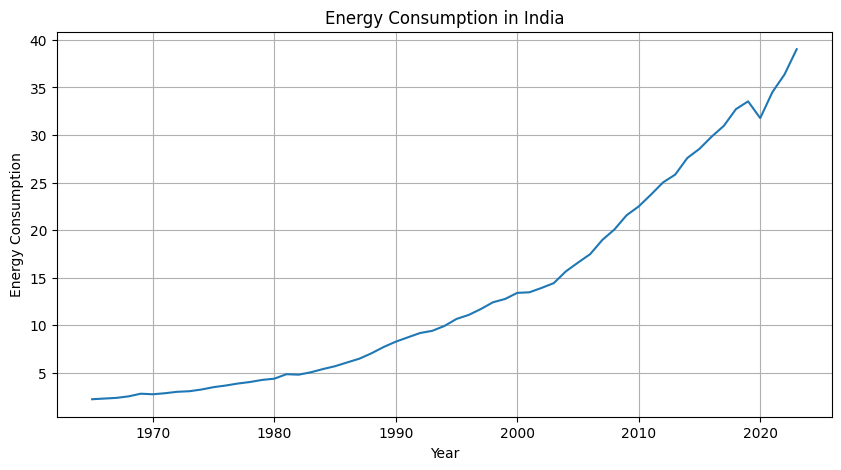

In [53]:
import matplotlib.pyplot as plt

# Select one country
country = "India"

country_data = data[data["Country"] == country]

plt.figure(figsize=(10, 5))
plt.plot(
    country_data["year"],
    country_data["consumption"]
)

plt.title("Energy Consumption in India")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.grid(True)
plt.show()